# Домашнее задание по теме «Деревья решений: регрессия и классификация»

В работе две части: регрессия на Wine Quality и классификация на Adult. Ты сравнишь настройки sklearn и допишешь учебные реализации деревьев.

**Максимальная оценка: 10 баллов.** Задачи 1–5 дают 1, 2, 2, 2 и 2 балла, теоретические вопросы ещё 1 балл. Баллы подзадач входят в баллы задания и не прибавляются к ним повторно.

## Часть I. Деревья регрессии

Импортируем библиотеки и [загрузим датасет Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).

Датасет Wine Quality содержит данные о португальских винах Vinho Verde. В датасете два отдельных файла: около 1 600 записей для красного вина и почти 4 900 для белого. На каждый образец приходится 11 физических и химических характеристик (фиксированная кислотность, летучая кислотность, цитрат, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и содержание алкоголя) и целевая метка `quality` — оценка дегустатора от 0 до 10 (на практике в диапазоне ~ 3–9).

Обычно Wine Quality используют для задач регрессии, чтобы предсказать точечную оценку. Или для бинарной классификации, например, чтобы определить «низкое» или «высокое» качество, где порог — это 6. Используем датасет для задачи регрессии и  предскажем переменную `quality`.



In [ ]:
%pip install numpy
%pip install pandas
%pip install -U scikit-learn
%pip install seaborn
%pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

Теперь загрузим датасет и проведём разведочный анализ данных (EDA) и препроцессинг.

In [ ]:
# 1. Ссылки на CSV
red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

# 1.1 Скачиваем через urllib, отключив проверку SSL-сертификата
import ssl
import io
import urllib.request

ssl_ctx = ssl._create_unverified_context()

def read_csv_skip_verify(url):
    raw = urllib.request.urlopen(url, context=ssl_ctx).read()
    return pd.read_csv(io.BytesIO(raw), sep=';')

# 2. Считываем в DataFrame, указывая разделитель ';'
df_red = read_csv_skip_verify(red_url)
df_white = read_csv_skip_verify(white_url)

# 3. Добавляем колонку с типом вина
df_red["type"] = "red"
df_white["type"] = "white"

# 4. Объединяем
df = pd.concat([df_red, df_white], ignore_index=True)

# Удаляем точные повторы до разбиения, чтобы они не попадали в разные части.
df = df.drop_duplicates().reset_index(drop=True)
df_dev, df_holdout = train_test_split(df, test_size=0.2, random_state=0)
df, df_val = train_test_split(df_dev, test_size=0.25, random_state=0)
df, df_val, df_holdout = df.copy(), df_val.copy(), df_holdout.copy()

# EDA проводим по train.
# 5. Проверка
print(df.shape)   # Сколько записей и признаков
df.head()

(3192, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
4636,6.9,0.380,0.28,8.30,0.062,22.0,166.0,0.99506,3.16,0.72,10.6,5,white
1685,6.3,0.390,0.35,5.90,0.040,82.5,260.0,0.99410,3.12,0.66,10.1,5,white
2373,6.8,0.180,0.37,1.50,0.027,37.0,93.0,0.99200,3.30,0.45,10.8,6,white
5311,4.9,0.235,0.27,11.75,0.030,34.0,118.0,0.99540,3.07,0.50,9.4,6,white
951,5.6,0.660,0.00,2.50,0.066,7.0,15.0,0.99256,3.52,0.58,12.9,5,red


In [ ]:
# Нет пропусков, один категориальный признак
df.info()

<class 'pandas.DataFrame'>
Index: 3192 entries, 4636 to 4846
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         3192 non-null   float64
 1   volatile acidity      3192 non-null   float64
 2   citric acid           3192 non-null   float64
 3   residual sugar        3192 non-null   float64
 4   chlorides             3192 non-null   float64
 5   free sulfur dioxide   3192 non-null   float64
 6   total sulfur dioxide  3192 non-null   float64
 7   density               3192 non-null   float64
 8   pH                    3192 non-null   float64
 9   sulphates             3192 non-null   float64
 10  alcohol               3192 non-null   float64
 11  quality               3192 non-null   int64  
 12  type                  3192 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 349.1 KB


In [ ]:
# Есть выбросы
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,3192.0,7.196413,1.282733,3.90000,6.4000,6.90000,7.700000,15.60000
volatile acidity,3192.0,0.345515,0.170873,0.08000,0.2300,0.30000,0.410000,1.58000
citric acid,3192.0,0.316773,0.150347,0.00000,0.2400,0.31000,0.392500,1.66000
residual sugar,3192.0,5.067011,4.548557,0.60000,1.8000,2.80000,7.500000,65.80000
chlorides,3192.0,0.056335,0.036254,0.00900,0.0380,0.04700,0.065000,0.61100
free sulfur dioxide,3192.0,30.247180,18.565375,1.00000,16.0000,28.00000,41.000000,289.00000
total sulfur dioxide,3192.0,114.675752,57.427871,6.00000,74.0000,117.00000,155.000000,440.00000
density,3192.0,0.994537,0.002982,0.98722,0.9922,0.99464,0.996725,1.03898
pH,3192.0,3.227102,0.161596,2.72000,3.1200,3.22000,3.330000,4.01000
sulphates,3192.0,0.534887,0.152340,0.25000,0.4300,0.51000,0.600000,2.00000


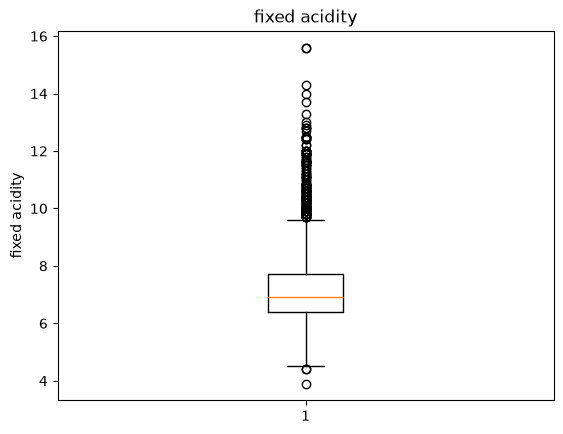

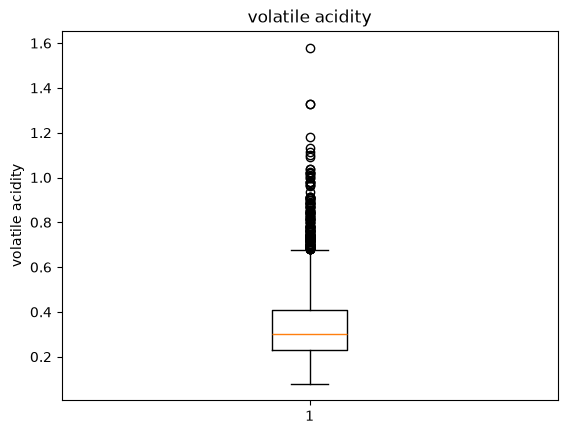

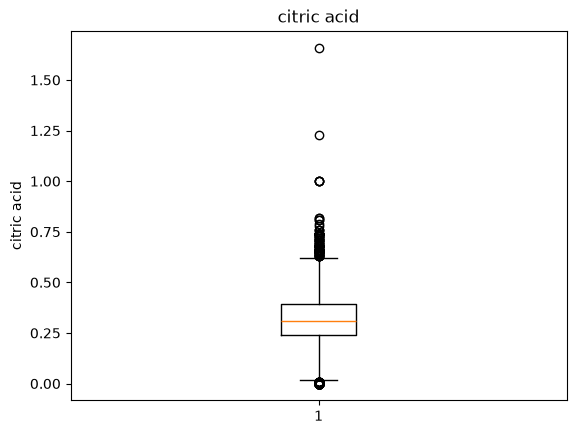

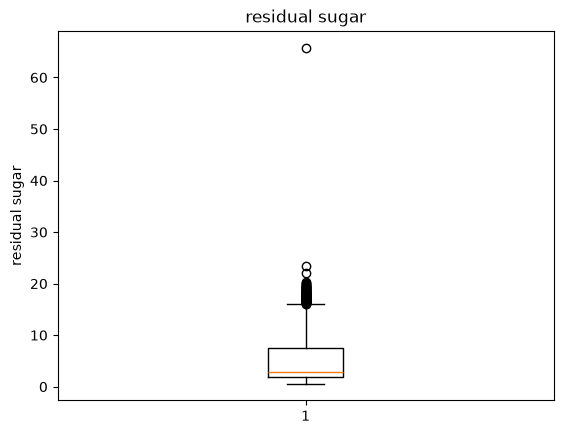

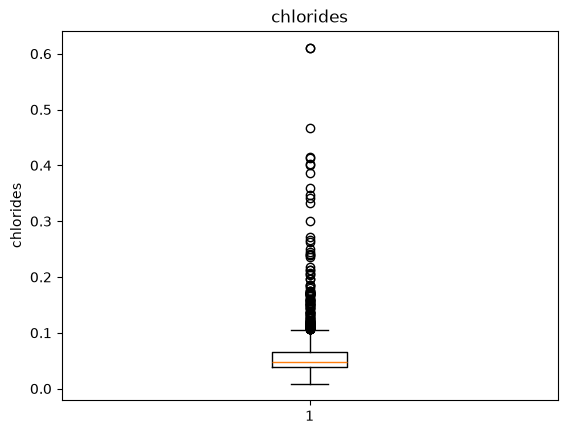

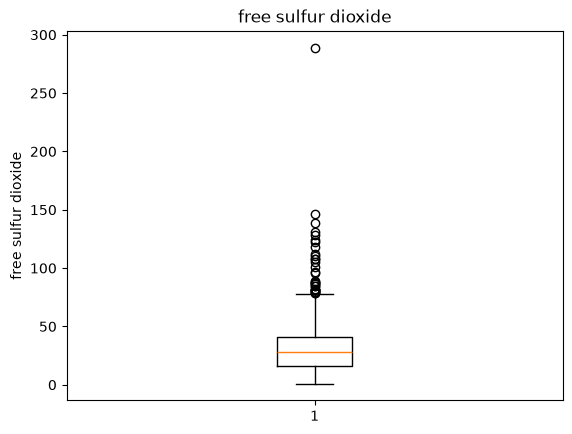

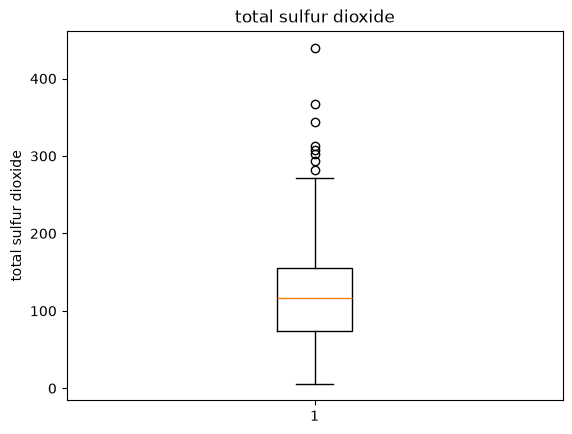

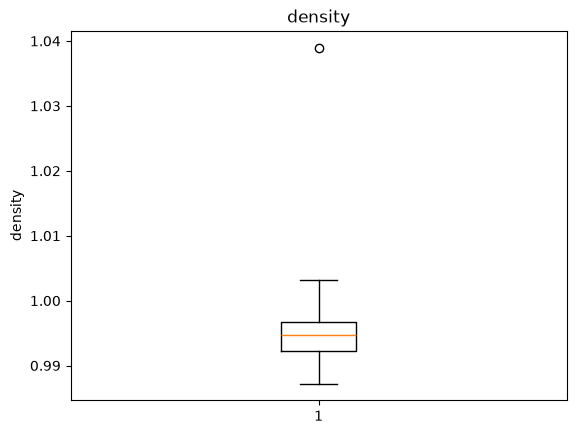

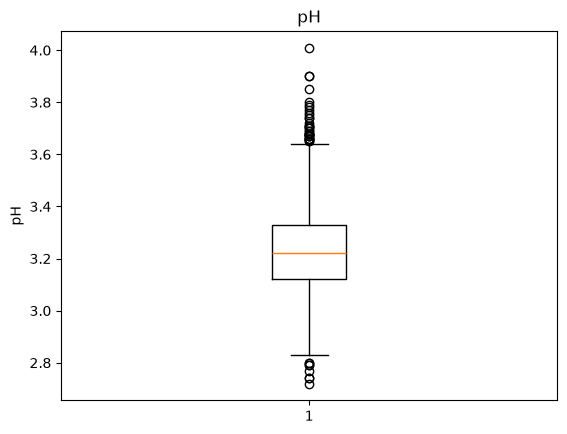

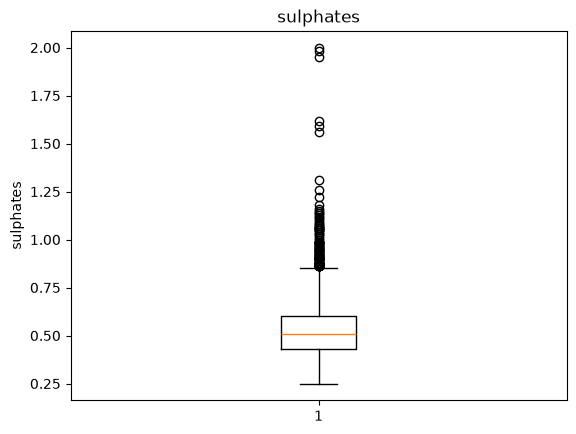

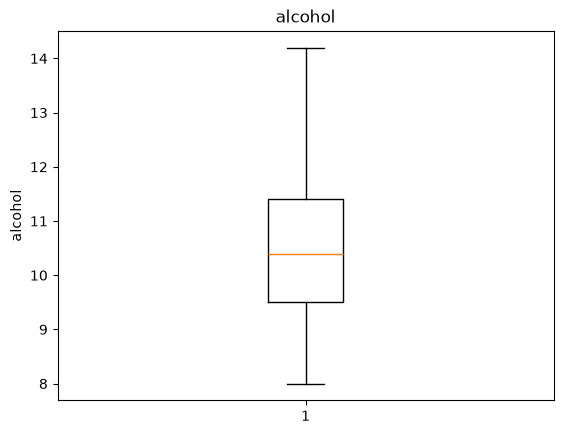

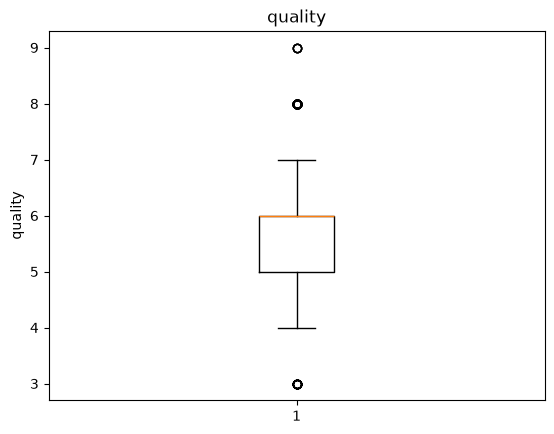

In [ ]:
# Много выбросов
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure()
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [ ]:
Q1, Q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
IQR = Q3 - Q1
mask = (df[num_cols] < (Q1 - 1.5*IQR)) | (df[num_cols] > (Q3 + 1.5*IQR))

print("Количество выбросов в каждом столбце")
print(mask.sum().sort_values(ascending=False))

Количество выбросов в каждом столбце
citric acid             223
fixed acidity           171
volatile acidity        169
chlorides               146
quality                 108
sulphates               104
residual sugar           86
pH                       43
free sulfur dioxide      32
total sulfur dioxide      8
density                   1
alcohol                   0
dtype: int64


Правило 1,5 IQR отмечает редкие значения, но не доказывает ошибку измерения. Без сведений об ошибках оставим наблюдения и исходные оценки quality. Склонность дерева к переобучению будем контролировать параметрами модели.

In [ ]:
# Сохраняем исходные значения признаков и quality.
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,3192.0,7.196413,1.282733,3.90000,6.4000,6.90000,7.700000,15.60000
volatile acidity,3192.0,0.345515,0.170873,0.08000,0.2300,0.30000,0.410000,1.58000
citric acid,3192.0,0.316773,0.150347,0.00000,0.2400,0.31000,0.392500,1.66000
residual sugar,3192.0,5.067011,4.548557,0.60000,1.8000,2.80000,7.500000,65.80000
chlorides,3192.0,0.056335,0.036254,0.00900,0.0380,0.04700,0.065000,0.61100
free sulfur dioxide,3192.0,30.247180,18.565375,1.00000,16.0000,28.00000,41.000000,289.00000
total sulfur dioxide,3192.0,114.675752,57.427871,6.00000,74.0000,117.00000,155.000000,440.00000
density,3192.0,0.994537,0.002982,0.98722,0.9922,0.99464,0.996725,1.03898
pH,3192.0,3.227102,0.161596,2.72000,3.1200,3.22000,3.330000,4.01000
sulphates,3192.0,0.534887,0.152340,0.25000,0.4300,0.51000,0.600000,2.00000


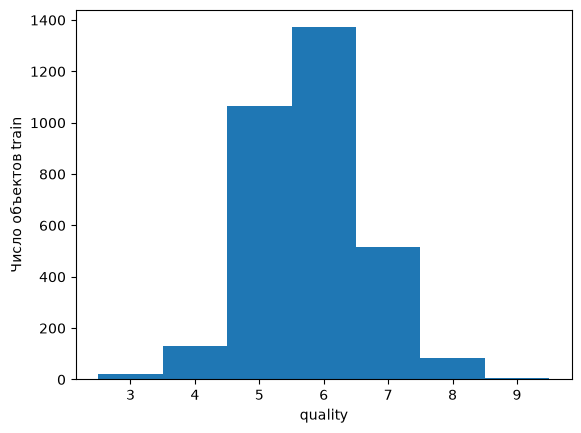

In [ ]:
plt.hist(df['quality'], bins=np.arange(2.5, 10.5, 1))
plt.xlabel('quality')
plt.ylabel('Число объектов train')
plt.show()

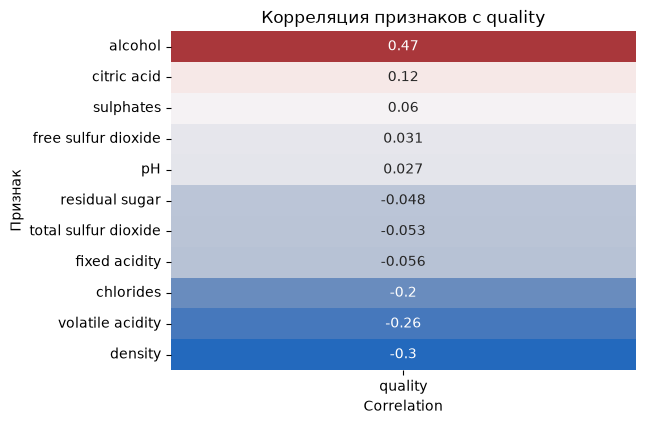

In [ ]:
# 1. Считаем матрицу корреляций
corr = df.corr(numeric_only=True)

# 2. Берём только столбец quality, убираем строку quality и сортируем
corr_q = corr["quality"].drop("quality").sort_values(ascending=False)

# 3. Рисуем теплокарту
plt.figure(figsize=(6, len(corr_q) * 0.4))
sns.heatmap(corr_q.to_frame(), annot=True, cmap="vlag", cbar=False)
plt.title("Корреляция признаков с quality")
plt.ylabel("Признак")
plt.xlabel("Correlation")
plt.show()

In [ ]:
# Два заранее известных типа вина кодируем одинаково во всех частях.
for frame in [df, df_val, df_holdout]:
    frame['type_white'] = (frame['type'] == 'white').astype(int)
    frame.drop(columns='type', inplace=True)
df.head()

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1784526234.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns='type', inplace=True)
/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1784526234.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns='type', inplace=True)
/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1784526234.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_white
4636,6.9,0.380,0.28,8.30,0.062,22.0,166.0,0.99506,3.16,0.72,10.6,5,1
1685,6.3,0.390,0.35,5.90,0.040,82.5,260.0,0.99410,3.12,0.66,10.1,5,1
2373,6.8,0.180,0.37,1.50,0.027,37.0,93.0,0.99200,3.30,0.45,10.8,6,1
5311,4.9,0.235,0.27,11.75,0.030,34.0,118.0,0.99540,3.07,0.50,9.4,6,1
951,5.6,0.660,0.00,2.50,0.066,7.0,15.0,0.99256,3.52,0.58,12.9,5,0


In [ ]:
X = df.drop(["quality"], axis=1)
y = df["quality"]

In [ ]:
X_train, y_train = X, y
X_val, y_val = df_val.drop(columns='quality'), df_val['quality']
X_holdout, y_holdout = df_holdout.drop(columns='quality'), df_holdout['quality']
print('Train / validation / test:', len(X_train), len(X_val), len(X_holdout))

Train / validation / test: 3192 1064 1064


### Задача 1. `sklearn`: неограниченное дерево [1 балл]  

Работаем с датасетом Wine Quality. Будем предсказывать оценку качества вина.

  




#### Задача 1.1 [0,5 балла]

- Обучи неограниченное дерево `DecisionTreeRegressor(random_state=42)` и выведи $R^2$ на validation.

- Выведи глубину дерева и число листьев.

In [ ]:
# Напиши код здесь
model = DecisionTreeRegressor(
    random_state=42
)
model.fit(X_train, y_train)
print('Глубина дерева:', model.get_depth())
print('Число листьев:', model.get_n_leaves())

y_val_predict = model.predict(X_val)
r2_val=r2_score(y_val, y_val_predict)
print(f'R^2 (validation): {r2_val:.4f}')

Глубина дерева: 22
Число листьев: 1042
R^2 (validation): -0.3140


Модел очевидно переучилась, R^2 отрицательный. Модель хуже avg.

#### Задача 1.2 [0,5 балла]

Отрисуй первые три уровня полученного дерева с помощью `plot_tree` (параметр `max_depth = 2`).

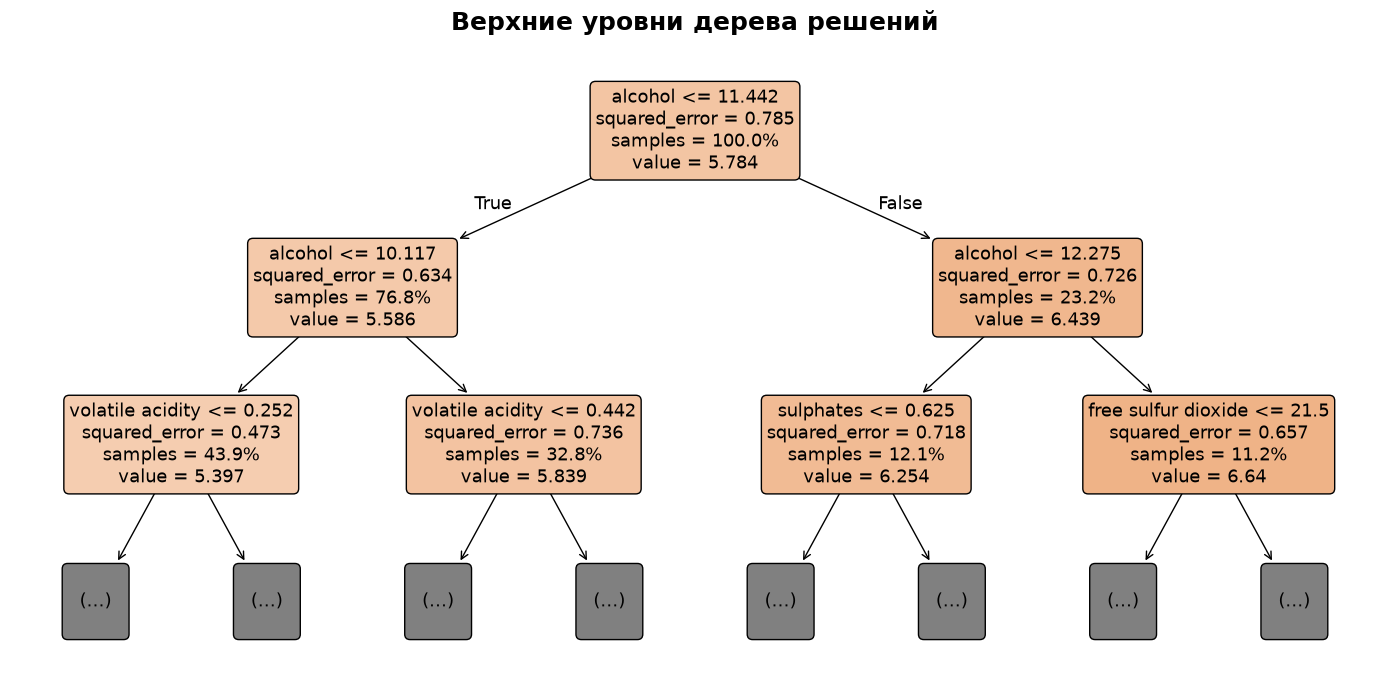

In [ ]:
# Напиши код здесь
plt.figure(figsize=(14, 7))

tree.plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=13,
    impurity=True,
    proportion=True,
)

plt.title("Верхние уровни дерева решений", fontsize=18, fontweight='bold', pad=16)
plt.axis('off')
plt.tight_layout()
plt.show()

### Задача 2. `sklearn`: ограниченное дерево [2 балла]  

Сравни неограниченное дерево с деревьями меньшей сложности на общей validation. Не используй итоговый test для выбора параметров.

#### Задача 2.1 [0,5 балла]

- Напиши цикл, который будет проходить по различным значениям `max_depth` (от 1 до 23).

- Для каждого значения глубины обучи `DecisionTreeRegressor` с заданной глубиной на обучающих данных.

- Вычисли $R^2$ только на валидационной выборке.

- Нарисуй график зависимости валидационного $R^2$ от глубины дерева.

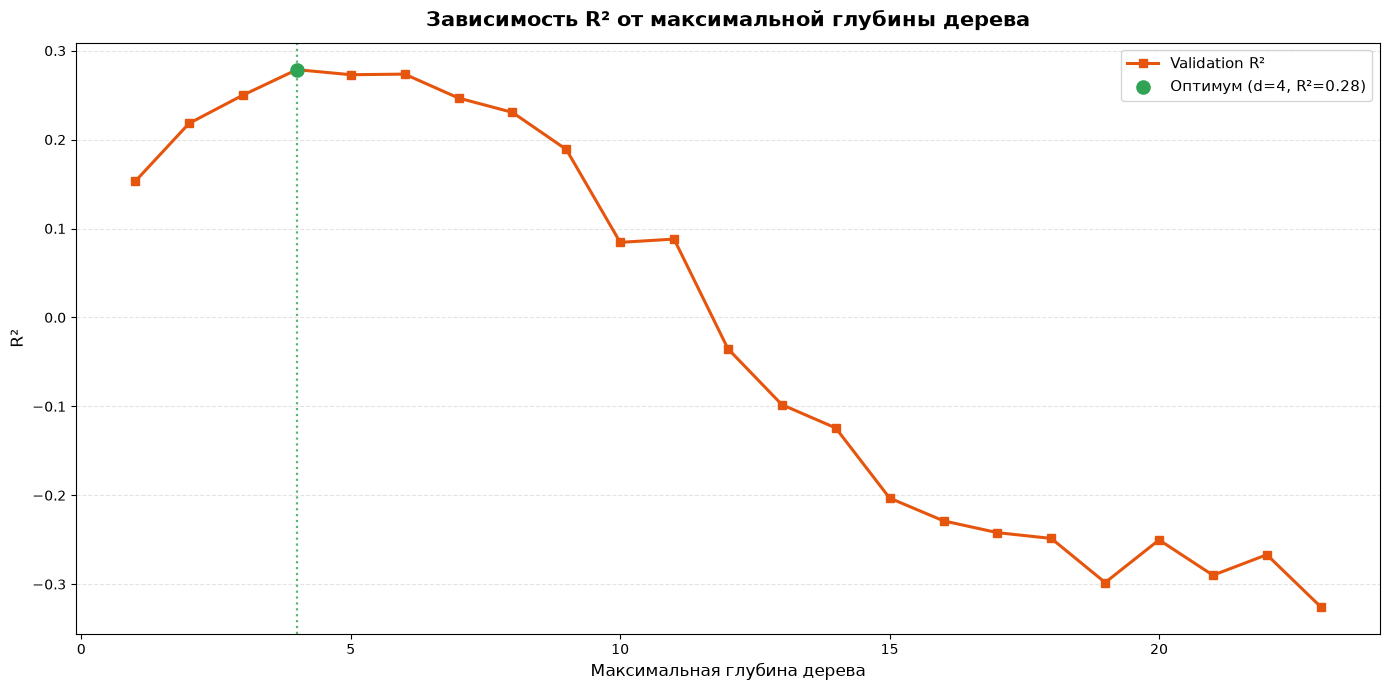

In [ ]:
# Напиши код здесь
r2_vals = []
depths = np.arange(1, 24)

for depth in range(1,24):
    model = DecisionTreeRegressor(max_depth=depth)
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    # print(f"max_depth = {depth}")
    r2_vals.append(r2_score(y_val, y_val_pred))
    # print(f"R2 = {r2_vals[-1]}")
    # print("-"*10)

best_idx = np.argmax(r2_vals)

plt.figure(figsize=(14, 7))
plt.plot(depths, r2_vals, label='Validation R²', marker='s', linewidth=2.2, color="#e6550d")

plt.scatter(depths[best_idx], r2_vals[best_idx], color="#31a354", s=90, zorder=5, label=f'Оптимум (d={depths[best_idx]}, R²={r2_vals[best_idx]:.2f})')
plt.axvline(depths[best_idx], color="#31a354", linestyle=':', linewidth=1.6, alpha=0.8)

plt.xlabel('Максимальная глубина дерева', fontsize=12)
plt.ylabel('R²', fontsize=12)
plt.title('Зависимость R² от максимальной глубины дерева', fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()


#### Задача 2.2 [0,5 балла]  

- Напиши аналогичный цикл для гиперпараметра `min_samples_split`. Массив значений, которые надо проверить: `splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]`.

- Нарисуй аналогичный график.

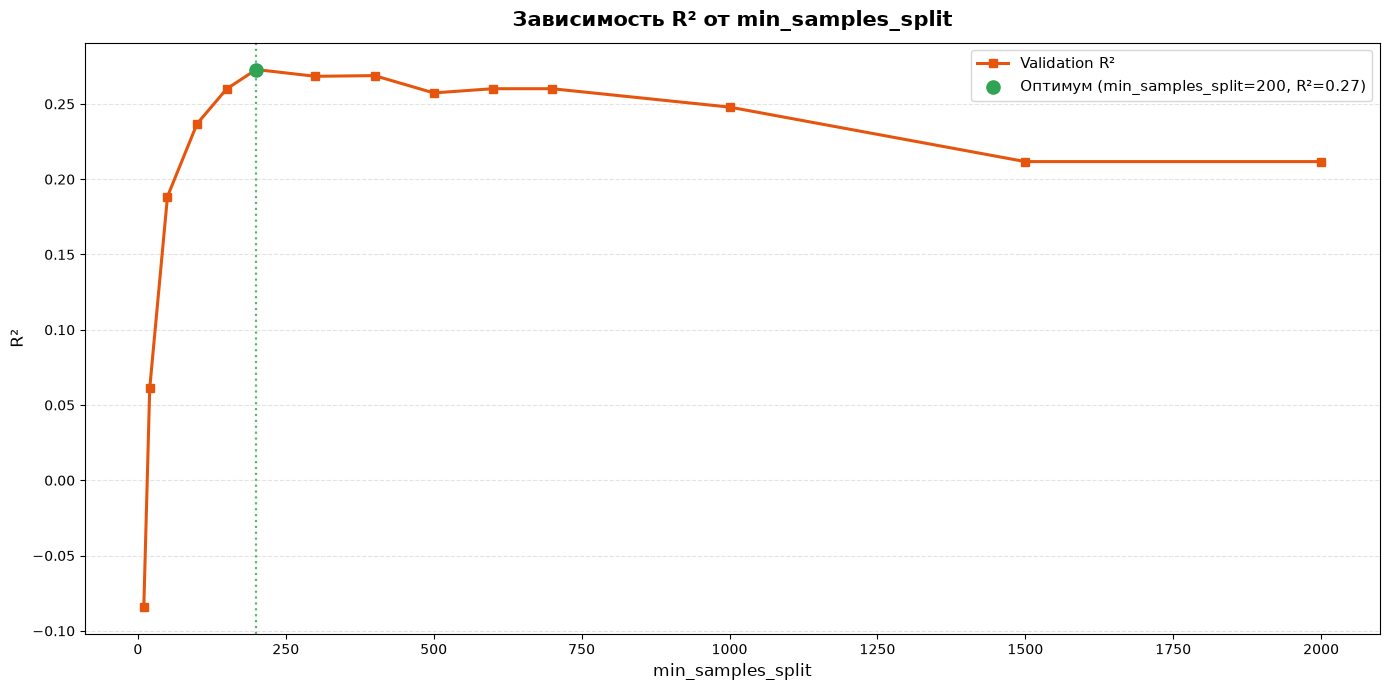

In [ ]:
# Напиши код здесь
r2_vals = []
splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]

for min_samples_split in splits:
    model = DecisionTreeRegressor(min_samples_split=min_samples_split)
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    # print(f"max_depth = {depth}")
    r2_vals.append(r2_score(y_val, y_val_pred))
    # print(f"R2 = {r2_vals[-1]}")
    # print("-"*10)

best_idx = np.argmax(r2_vals)

plt.figure(figsize=(14, 7))
plt.plot(splits, r2_vals, label='Validation R²', marker='s', linewidth=2.2, color="#e6550d")

plt.scatter(splits[best_idx], r2_vals[best_idx], color="#31a354", s=90, zorder=5, label=f'Оптимум (min_samples_split={splits[best_idx]}, R²={r2_vals[best_idx]:.2f})')
plt.axvline(splits[best_idx], color="#31a354", linestyle=':', linewidth=1.6, alpha=0.8)

plt.xlabel('min_samples_split', fontsize=12)
plt.ylabel('R²', fontsize=12)
plt.title('Зависимость R² от min_samples_split', fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()


#### Задача 2.3 [0,5 балла]

**Вопрос.** Как можно объяснить два нарисованных графика?

Дерево склонно к переобучению, поэтому на валидационной выборке можно говорить, что промежуток от [1, 3) - соответствует недообучению, наилучшее значение выборки при d = 5, ну и дальше дерево заметно переобучается.

min sample split величина пропорциональная глубине дерева, выводы аналогичны, наилучший результат при min_samples_split = 200. До этого значения дерево недообучено, после медленно переробучается, можно заметить, что темп переобучение меньше, чем при увеличении глубины.

#### Задача 2.4 [0,5 балла]

Подбери гиперпараметры с Optuna, максимизируя средний R² по `KFold(n_splits=5, shuffle=True, random_state=42)` на train. Используй до 300 попыток и 600 секунд. Для воспроизводимости задай `TPESampler(seed=42)`. После поиска выведи `study.best_params` и `study.best_value`.

In [ ]:
!pip install optuna --quiet

import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [ ]:
# Напиши код здесь
def objective(trial):

    # Пространство поиска
    params = {

        "max_depth": trial.suggest_int("max_depth", 2, 23),
        "min_samples_split": trial.suggest_int("min_samples_split", 250, 550)
    }

    model = DecisionTreeRegressor(random_state=42, **params)

    # 5-кратная кросс-валидация, метрика — R^2
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    r2 = cross_val_score(model, X_train, y_train,
                               scoring="r2",
                               cv=cv, n_jobs=-1)

    return r2.mean()

# Запускаем исследование (300 trials)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=300, timeout=600)

print("Лучшее значение R^2:", study.best_value)
print("Лучшие гиперпараметры:", study.best_params)

[I 2026-10-24 08:40:22,215] A new study created in memory with name: no-name-d1a12d9f-da8c-41cc-80f8-be9609f4a810
[I 2026-10-24 08:40:22,244] Trial 0 finished with value: 0.24754359998599976 and parameters: {'max_depth': 10, 'min_samples_split': 536}. Best is trial 0 with value: 0.24754359998599976.
[I 2026-10-24 08:40:22,271] Trial 1 finished with value: 0.2397204187255891 and parameters: {'max_depth': 18, 'min_samples_split': 430}. Best is trial 0 with value: 0.24754359998599976.
[I 2026-10-24 08:40:22,296] Trial 2 finished with value: 0.23817240464352968 and parameters: {'max_depth': 5, 'min_samples_split': 296}. Best is trial 0 with value: 0.24754359998599976.
[I 2026-10-24 08:40:22,310] Trial 3 finished with value: 0.2319372325684661 and parameters: {'max_depth': 3, 'min_samples_split': 510}. Best is trial 0 with value: 0.24754359998599976.
[I 2026-10-24 08:40:22,323] Trial 4 finished with value: 0.23486539933507408 and parameters: {'max_depth': 15, 'min_samples_split': 463}. Best

Лучшее значение R^2: 0.24951984427409862
Лучшие гиперпараметры: {'max_depth': 14, 'min_samples_split': 538}


### Задача 3. Свой `DecisionTreeRegressor` [2 балла]  

Задача 3 состоит из трёх подзадач. В подзадаче 3.1 и 3.2 ты напишешь методы класса, а в подзадаче 3.3 вставишь эти методы в скелет класса. Этот скелет моделирует работу деревьев регрессии. Твоя цель — дописать в этот класс два метода (из подзадач 3.1 и 3.2), которые позволяют дереву расти.



In [ ]:
# Вспомогательные функции и классы
from dataclasses import dataclass

def rss(y):
    """Residual Sum of Squares."""
    y = np.asarray(y)
    mu = y.mean()
    return np.sum((y - mu) ** 2)

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None

In [ ]:
# Меняем только представление данных. Разбиение сохраняется.
X_train = np.asarray(X_train, dtype=float)
X_val = np.asarray(X_val, dtype=float)
X_holdout = np.asarray(X_holdout, dtype=float)
y_train, y_val, y_holdout = map(np.asarray, (y_train, y_val, y_holdout))

#### Задача 3.1 [1 балл]

- Реализуй метод `_best_split(X, y, feat_idxs)`. Метод на данном шаге ищет признак и порог, минимизирующие сумму RSS в дочерних узлах.

- Используй уже написанный метод RSS, рассчитывающий сумму квадратов остатков предсказаний.

In [ ]:
# Зададим какой-то гиперпараметр min_samples_leaf
min_samples_leaf = 500

# Напиши код здесь
# Перед тем, как начать заполнять функцию, вспомни теорию построения дерева из
# лонгрида и продумай алгоритм построения дерева регрессии

# feat_idxs — номера столбцов (признаков)
# Х и у — наблюдения в текущем узле
def _best_split(X, y, feat_idxs):
    # Лучший признак по которому надо делить, лучший порог, лучшая мера неопределённости
    best_feat, best_thr, best_rss = None, None, np.inf
    n = len(y)

    # Для каждого признака выполняем
    for f in feat_idxs:
        # Сортируй по текущему признаку
        # Сортировка позволит «идти» слева направо по значениям признака и выбирать порог
        # https://numpy.org/devdocs/reference/generated/numpy.argsort.html

        order = np.argsort(X[:, f])
        x_sorted = X[order, f]
        y_sorted = y[order]

        # Идём слева направо и смотрим на результативность порогов признака
        for i in range(min_samples_leaf,
                        n - min_samples_leaf + 1):
            # Напиши if, который сработает, если два разных наблюдения будут иметь
            # одно и то же значение признака. Нужно ли тогда повторно проверять
            # результативность применения одного и того же порога признака?

            if x_sorted[i] == x_sorted[i - 1]:
                continue

            left_y  = y_sorted[:i]
            right_y = y_sorted[i:]

            # Напиши, чему будет равен общий RSS двух потомственных сплитов. Нужна
            # ли здесь нормировка?
            # После общего RSS проверь, является ли этот RSS наименьшим среди всех возможных
            # сплитов, (сравни с best_rss) и, если да, обнови best_rss, best_feat и best_thr

            totalrss = rss(left_y)+rss(right_y)
            if totalrss < best_rss:
                best_rss = totalrss
                best_feat = f
                best_thr  = (x_sorted[i - 1] + x_sorted[i]) / 2

    return best_feat, best_thr

#### Задача 3.2 [1 балл]

Реализуй рекурсивный метод `_fit_node(X, y, depth)`, который строит всё дерево.    

In [ ]:
# Зададим гиперпараметры
max_depth = 5
min_samples_split = 500

# Напиши код здесь

# Сейчас мы используем предыдущую функцию для того, чтобы рекурсивно построить дерево
# X, y — наблюдения в текущем узле, в начале подаётся полный датасет
# depth = 0 в начале, по мере роста дерева увеличивается
def _fit_node(X, y, depth):
    # Создаем узел
    node = NodeR()

    # Напиши стоп-условия, которые остановят рост дерева и вернут значение листа
    # Подсказка: стоп-условия связаны с гиперпараметрами выше

    if depth == max_depth or len(y) < min_samples_split or np.unique(y).size == 1:
        node.value = y.mean()
        return node


    # Реализуй функцию _best_split()

    feat, thr = _best_split(X, y, np.arange(X.shape[1]))

    if feat is None:     # Если сплит не найден
        node.value = y.mean()
        return node

    node.feat, node.thr = feat, thr
    mask = X[:, feat] <= thr

    # Реализуй рекурсивную функцию _fit_node, которая будет делить узел на два
    # подузла и для каждого подузла реализовывать тот же функционал

    node.left  = _fit_node(X[mask], y[mask], depth + 1)
    node.right = _fit_node(X[~mask], y[~mask], depth + 1)
    return node

#### Задача 3.3 [Обязательная]

Перенеси функции из 3.1 и 3.2 в методы `MyDecisionTreeRegressor`. Добавь `self` и используй `self.min_samples_leaf`, `self.min_samples_split`, `self.max_depth`, `self.rss`.

Обучи класс на прежнем train и рассчитай R² на validation. Сравни со sklearn при одинаковых `max_depth=5`, `min_samples_split=2`, `min_samples_leaf=1`.

Сборка класса обязательна: без неё максимум за задачу 3 составляет 1 балл. Без оценки на validation максимум составляет 1,5 балла.

In [ ]:
from dataclasses import dataclass

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None


class MyDecisionTreeRegressor:
    def __init__(self, max_depth=5, min_samples_split=2,
                 min_samples_leaf=1, random_state=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state  # В этой реализации разбиения детерминированы
        self.root = None

    @staticmethod
    def rss(y):
        """Residual Sum of Squares."""
        mu = y.mean()
        return np.sum((y - mu) ** 2)

    # ---------- 3.1 ----------
    def _best_split(self, X, y, feat_idxs):
        best_feat, best_thr, best_rss = None, None, np.inf
        n = len(y)
        for f in feat_idxs:
            order = np.argsort(X[:, f])
            x_sorted = X[order, f]
            y_sorted = y[order]
            for i in range(self.min_samples_leaf,
                            n - self.min_samples_leaf + 1):
                if x_sorted[i] == x_sorted[i - 1]:
                    continue

                left_y  = y_sorted[:i]
                right_y = y_sorted[i:]
                totalrss = self.rss(left_y) + self.rss(right_y)
                if totalrss < best_rss:
                    best_rss = totalrss
                    best_feat = f
                    best_thr  = (x_sorted[i - 1] + x_sorted[i]) / 2

        return best_feat, best_thr

    # ---------- 3.2 ----------
    def _fit_node(self, X, y, depth):
        node = NodeR()
        if depth == self.max_depth or len(y) < self.min_samples_split or np.unique(y).size == 1:
            node.value = y.mean()
            return node
        feat, thr = self._best_split(X, y, np.arange(X.shape[1]))
        if feat is None:
            node.value = y.mean()
            return node
        node.feat, node.thr = feat, thr
        mask = X[:, feat] <= thr
        node.left  = self._fit_node(X[mask], y[mask], depth + 1)
        node.right = self._fit_node(X[~mask], y[~mask], depth + 1)
        return node

    # ---- Публичные методы fit/predict ----

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.root = self._fit_node(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        if node.left is None:
            return node.value
        return self._predict_one(x, node.left if x[node.feat] <= node.thr else node.right)

    def predict(self, X):
        if self.root is None:
            raise ValueError("Сначала вызови fit")
        return np.array([self._predict_one(x, self.root) for x in np.asarray(X)])

In [ ]:
# Напиши функцию здесь
# Создай объект класса, обучи его и протестируй
custom = MyDecisionTreeRegressor(max_depth=5, min_samples_split=2, min_samples_leaf=1)
custom.fit(X_train, y_train)
y_predict_val_custom = custom.predict(X_val)
r2_custom = r2_score(y_val, y_predict_val_custom)


sk = DecisionTreeRegressor(max_depth=5, min_samples_split=2, min_samples_leaf=1)
sk.fit(X_train, y_train)
y_predict_val_sk = sk.predict(X_val)
r2_sk = r2_score(y_val, y_predict_val_sk)

print(f"R^2 custom : {r2_custom:.4f}")
print(f"R^2 sklearn: {r2_sk:.4f}")
print(f"diff: {abs(r2_custom - r2_sk):.4f}")



R^2 custom : 0.2752
R^2 sklearn: 0.2752
diff: 0.0000


Сравни R² учебной и библиотечной моделей на одинаковом разбиении. Близкие метрики сами по себе не доказывают совпадения деревьев. При равноценных разбиениях реализации могут выбрать разные признаки. Для проверки алгоритма нужны также небольшие примеры с известным оптимальным порогом. После этого однократно оцени выбранное Optuna дерево на test, не меняя настройки по результату.

In [ ]:
best_clf = DecisionTreeRegressor(random_state=42, **study.best_params)
best_clf.fit(X_train, y_train)
r2_holdout = r2_score(y_holdout, best_clf.predict(X_holdout))
print(f"Optuna R^2 (holdout): {r2_holdout:.4f}")

Optuna R^2 (holdout): 0.2224


## Часть II. Деревья классификации

Для второй части домашнего задания тебе понадобится [датасет Adult](https://archive.ics.uci.edu/dataset/2/adult) (`adult`).

Датасет Adult (он же Census Income) — классический набор данных, собранный во время переписи населения США 1994 года. В нём около 48 000 записей и 14 признаков: возраст, род занятий, уровень образования, семейный статус, профессия, родственники в семье, раса, пол, доходы от капитала, убытки от капитала, количество рабочих часов в неделю и страна рождения. Целевая метка — бинарная: получает человек более 50 000 $ в год или нет.

Чаще всего Adult используют для обучения и сравнения бинарных классификаторов (логистическая регрессия, деревья решений, бустинг), а ещё как тест на обработку категориальных признаков (one-hot, целевое кодирование) и работу с пропущенными значениями (в датасете некоторые поля обозначены `?`). Класс `>50K` составляет около четверти выборки, что даёт умеренный дисбаланс и повод поэкспериментировать с метриками (precision/recall, ROC-AUC).




In [ ]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [ ]:
# 1. Список имён колонок из adult.names
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

# 2. URL-адреса
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url  = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

def read_csv_skip_verify(url):
    raw = urllib.request.urlopen(url, context=ssl_ctx).read()
    return pd.read_csv(
        io.BytesIO(raw),
        names=columns,
        sep=',',
        na_values='?',
        skipinitialspace=True,
        skiprows=1  # Пропустить строку заголовка в файле .test
    )

# 3. Скачиваем и читаем
df_train = read_csv_skip_verify(train_url)
df_test = read_csv_skip_verify(test_url)
# В учебном эксперименте используем собственное разбиение объединённых данных.
# Это не оценка на официальном test-разбиении Adult.
df = pd.concat([df_train, df_test], ignore_index=True)
df['income'] = df['income'].str.strip().str.rstrip('.')
df = df.drop_duplicates().reset_index(drop=True)
df_dev, df_holdout = train_test_split(df, test_size=0.2, random_state=42, stratify=df['income'])
df, df_val = train_test_split(df_dev, test_size=0.25, random_state=42, stratify=df_dev['income'])
df, df_val, df_holdout = df.copy(), df_val.copy(), df_holdout.copy()

In [ ]:
num_cols = df.select_dtypes('number').columns
cat_cols = df.select_dtypes('object').columns.drop('income')

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1911140012.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes('object').columns.drop('income')


In [ ]:
print(df.shape)
df.head()

(29273, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
35909,35,Private,107302,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,40,United-States,>50K
18162,52,Private,155233,Some-college,10,Divorced,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
11146,37,Private,302604,Some-college,10,Separated,Other-service,Other-relative,White,Female,0,0,40,United-States,<=50K
25021,35,Private,258339,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,55,United-States,>50K
30108,31,Private,130021,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,45,United-States,<=50K


Начнём с изучения целевой переменной.

In [ ]:
df['income']

35909     >50K
18162    <=50K
11146    <=50K
25021     >50K
30108    <=50K
         ...  
19261    <=50K
42001     >50K
29985    <=50K
36019     >50K
32610    <=50K
Name: income, Length: 29273, dtype: str

In [ ]:
df['income'] = df['income'].str.strip().str.rstrip('.')

income
<=50K    0.760564
>50K     0.239436
Name: proportion, dtype: float64


<Axes: xlabel='income'>

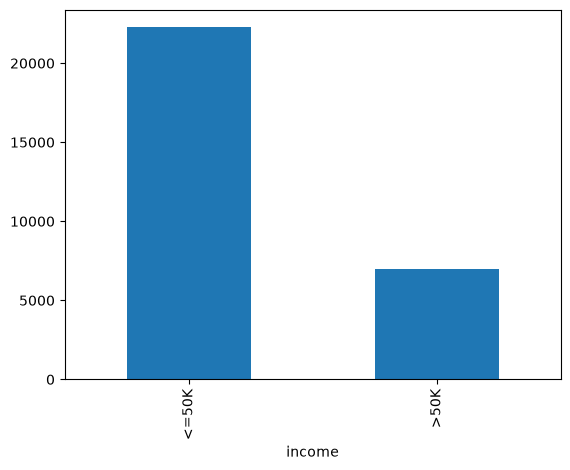

In [ ]:
print(df['income'].value_counts(normalize=True))
df['income'].value_counts().plot(kind='bar')

В дальнейшем будем учитывать, что в датасете гораздо больше людей с доходом `<=50K ` (то есть классы несбалансированы).


Теперь посмотрим на пропуски.

In [ ]:
for frame in [df, df_val, df_holdout]:
    frame.replace('?', np.nan, inplace=True)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 29273 entries, 35909 to 32610
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             29273 non-null  int64
 1   workclass       27583 non-null  str  
 2   fnlwgt          29273 non-null  int64
 3   education       29273 non-null  str  
 4   education_num   29273 non-null  int64
 5   marital_status  29273 non-null  str  
 6   occupation      27579 non-null  str  
 7   relationship    29273 non-null  str  
 8   race            29273 non-null  str  
 9   sex             29273 non-null  str  
 10  capital_gain    29273 non-null  int64
 11  capital_loss    29273 non-null  int64
 12  hours_per_week  29273 non-null  int64
 13  native_country  28756 non-null  str  
 14  income          29273 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.6 MB


In [ ]:
for frame in [df, df_val, df_holdout]:
    frame[cat_cols] = frame[cat_cols].fillna('Unknown')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 29273 entries, 35909 to 32610
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             29273 non-null  int64
 1   workclass       29273 non-null  str  
 2   fnlwgt          29273 non-null  int64
 3   education       29273 non-null  str  
 4   education_num   29273 non-null  int64
 5   marital_status  29273 non-null  str  
 6   occupation      29273 non-null  str  
 7   relationship    29273 non-null  str  
 8   race            29273 non-null  str  
 9   sex             29273 non-null  str  
 10  capital_gain    29273 non-null  int64
 11  capital_loss    29273 non-null  int64
 12  hours_per_week  29273 non-null  int64
 13  native_country  29273 non-null  str  
 14  income          29273 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.6 MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,29273.0,38.727086,13.716362,17.0,28.0,37.0,48.0,90.0
fnlwgt,29273.0,189603.727633,104967.418284,14878.0,117496.0,178623.0,237868.0,1484705.0
education_num,29273.0,10.078981,2.558801,1.0,9.0,10.0,12.0,16.0
capital_gain,29273.0,1051.290131,7344.602313,0.0,0.0,0.0,0.0,99999.0
capital_loss,29273.0,89.008472,405.402147,0.0,0.0,0.0,0.0,4356.0
hours_per_week,29273.0,40.433539,12.374432,1.0,40.0,40.0,45.0,99.0


In [ ]:
# Есть ли опечатки в названиях категорий? Редкие категории?
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


workclass
Private             20283
Self-emp-not-inc     2335
Local-gov            1842
Unknown              1690
State-gov            1192
Self-emp-inc         1027
Federal-gov           885
Without-pay            15
Never-worked            4
Name: count, dtype: int64


 education


education
HS-grad         9475
Some-college    6543
Bachelors       4773
Masters         1612
Assoc-voc       1235
11th            1109
Assoc-acdm       969
10th             816
7th-8th          559
Prof-school      483
Name: count, dtype: int64


 marital_status


...

race
White                 25036
Black                  2809
Asian-Pac-Islander      912
Amer-Indian-Eskimo      272
Other                   244
Name: count, dtype: int64


 sex


sex
Male      19657
Female     9616
Name: count, dtype: int64


 native_country


native_country
United-States    26275
Mexico             558
Unknown            517
Philippines        196
Germany            133
Puerto-Rico        115
Canada             111
El-Salvador         88
India               83
Cuba                81
Name: count, dtype: int64

Большое число категорий увеличивает размер one-hot представления. Объединим категории, которые занимают меньше 1% train, и применим те же правила к отложенным данным.

In [ ]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    counts = df[col].str.strip().value_counts()
    frequent = counts[counts >= 0.01*len(df)].index
    for frame in [df, df_val, df_holdout]:
        values = frame[col].str.strip()
        frame[col] = values.where(values.isin(frequent), 'other')

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/672389353.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes('object').columns.drop('income')


In [ ]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/3879134197.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes('object').columns.drop('income')


workclass
Private             20283
Self-emp-not-inc     2335
Local-gov            1842
Unknown              1690
State-gov            1192
Self-emp-inc         1027
Federal-gov           885
other                  19
Name: count, dtype: int64


 education


education
HS-grad         9475
Some-college    6543
Bachelors       4773
Masters         1612
Assoc-voc       1235
11th            1109
Assoc-acdm       969
10th             816
7th-8th          559
Prof-school      483
Name: count, dtype: int64

...

race
White                 25036
Black                  2809
Asian-Pac-Islander      912
other                   516
Name: count, dtype: int64


 sex


sex
Male      19657
Female     9616
Name: count, dtype: int64


 native_country


native_country
United-States    26275
other             1923
Mexico             558
Unknown            517
Name: count, dtype: int64

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


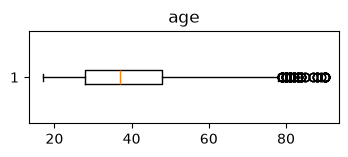

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


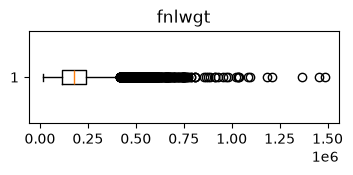

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


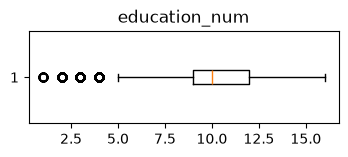

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


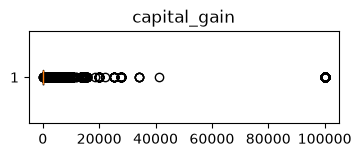

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


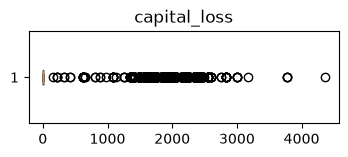

/var/folders/vr/l2ykxqv56s70rd4k6bfq_q0m0000gq/T/ipykernel_81550/1788645533.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


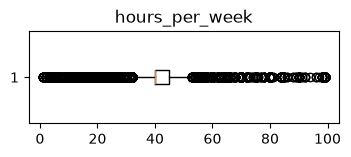

In [ ]:
# Распределения числовых переменных
for col in num_cols:
    plt.figure(figsize=(4,1.2))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(col); plt.show()

In [ ]:
(df['capital_gain'] > 0).astype(int).value_counts()

capital_gain
0    26888
1     2385
Name: count, dtype: int64

In [ ]:
def add_features(frame):
    # age: разбиение на отрезки
    frame['age_bin'] = pd.cut(frame['age'], bins=[16,25,35,45,55,65,100],
                           labels=['17-25','26-35','36-45','46-55','56-65','66+'])

    # В этой модели исключаем вес переписного наблюдения fnlwgt.
    frame = frame.drop('fnlwgt', axis=1)

    # capital_gain/capital_loss → флаги
    frame['gain_flag'] = (frame['capital_gain'] > 0).astype(int)
    frame['loss_flag'] = (frame['capital_loss'] > 0).astype(int)

    # hours_per_week: разбиение на отрезки
    frame['hours_bin'] = pd.cut(frame['hours_per_week'],
                             bins=[0,40,55,168],
                             labels=['<=40','41-55','56+'])
    return frame

df, df_val, df_holdout = [add_features(frame) for frame in [df, df_val, df_holdout]]

In [ ]:
# Проверим результат
df[['age','age_bin', 'capital_gain','gain_flag','capital_loss','loss_flag',
          'hours_per_week','hours_bin']].head()

,age,age_bin,capital_gain,gain_flag,capital_loss,loss_flag,hours_per_week,hours_bin
35909,35,26-35,0,0,0,0,40,<=40
18162,52,46-55,0,0,0,0,40,<=40
11146,37,36-45,0,0,0,0,40,<=40
25021,35,26-35,0,0,0,0,55,41-55
30108,31,26-35,0,0,0,0,45,41-55


Выделим таргет отдельно от признаков. One-hot столбцы определим по train. Validation и test приведём к тем же столбцам, а отсутствующие заполним нулями.

In [ ]:
y_train = (df['income'] == '>50K').astype(int)
y_val = (df_val['income'] == '>50K').astype(int)
y_holdout = (df_holdout['income'] == '>50K').astype(int)
X_train = pd.get_dummies(df.drop(columns='income'), dtype=int)
X_val = pd.get_dummies(df_val.drop(columns='income'), dtype=int).reindex(columns=X_train.columns, fill_value=0)
X_holdout = pd.get_dummies(df_holdout.drop(columns='income'), dtype=int).reindex(columns=X_train.columns, fill_value=0)
X_train.head()

,age,education_num,capital_gain,capital_loss,hours_per_week,gain_flag,loss_flag,workclass_Federal-gov,workclass_Local-gov,workclass_Private,...,native_country_other,age_bin_17-25,age_bin_26-35,age_bin_36-45,age_bin_46-55,age_bin_56-65,age_bin_66+,hours_bin_<=40,hours_bin_41-55,hours_bin_56+
35909,35,13,0,0,40,0,0,0,0,1,...,0,0,1,0,0,0,0,1,0,0
18162,52,10,0,0,40,0,0,0,0,1,...,0,0,0,0,1,0,0,1,0,0
11146,37,10,0,0,40,0,0,0,0,1,...,0,0,0,1,0,0,0,1,0,0
25021,35,15,0,0,55,0,0,0,0,1,...,0,0,1,0,0,0,0,0,1,0
30108,31,9,0,0,45,0,0,0,0,1,...,0,0,1,0,0,0,0,0,1,0


In [ ]:
X_train.info(verbose=False)

<class 'pandas.DataFrame'>
Index: 29273 entries, 35909 to 32610
Columns: 76 entries, age to hours_bin_56+
dtypes: int64(76)
memory usage: 17.2 MB


In [ ]:
print("Число признаков:", X_train.shape[1])

Число признаков: 76


In [ ]:
print('Train / validation / test:', len(X_train), len(X_val), len(X_holdout))

Train / validation / test: 29273 9758 9758


### Задача 4. `sklearn`: ограниченное дерево [2 балла]

Применим post-pruning. Сначала растёт полное дерево, затем из него удаляются ветви с учётом штрафа за число листьев. Параметр `ccp_alpha` управляет величиной этого штрафа. Последовательность допустимых значений возвращает `cost_complexity_pruning_path(X_train, y_train)`.

#### Задача 4.1 [1 балл]

Для критериев Джини и энтропии получи путь обрезки дерева на train. В этом эксперименте используй `class_weight='balanced'` и `random_state=42` во всех сравниваемых моделях.

Для каждого критерия возьми не более 300 равномерно расположенных индексов массива уникальных неотрицательных `ccp_alphas`. Если значений меньше 300, используй все. Для каждого alpha обучи дерево и рассчитай ROC-AUC по `predict_proba(X_val)[:, 1]`.

Сохрани `val_gini`, `val_entropy` той же длины, что соответствующие массивы alpha. Accuracy при дисбалансе может скрывать ошибки редкого класса. Здесь сравниваем ранжирование по ROC-AUC, а затем рассмотрим ошибки классов в confusion matrix. Сам дисбаланс не делает accuracy бессмысленной.

In [ ]:
from sklearn.metrics import roc_auc_score
# Напиши код здесь
def pruning_alphas(criterion, max_count=300):
    clf = DecisionTreeClassifier(criterion=criterion,
                                 class_weight='balanced',
                                 random_state=42)
    clf.fit(X_train, y_train)
    path = clf.cost_complexity_pruning_path(X_train, y_train)
    alphas = np.unique(path.ccp_alphas)
    alphas = alphas[alphas >= 0]
    if len(alphas) > max_count:
        idx = np.linspace(0, len(alphas) - 1, max_count, dtype=int)
        alphas = alphas[idx]
    return alphas

def val_auc_by_alpha(criterion, alphas):
    scores = []
    for alpha in alphas:
        clf = DecisionTreeClassifier(criterion=criterion,
                                     class_weight='balanced',
                                     ccp_alpha=alpha,
                                     random_state=42)
        clf.fit(X_train, y_train)
        y_pred = clf.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, y_pred)
        scores.append(score)
    return scores

alphas_gini = pruning_alphas('gini')
val_gini = val_auc_by_alpha('gini', alphas_gini)

alphas_entropy = pruning_alphas('entropy')
val_entropy = val_auc_by_alpha('entropy', alphas_entropy)

print(f"gini: {len(val_gini)} alpha, best AUC = {max(val_gini):.4f}")
print(f"entropy: {len(val_entropy)} alpha, best AUC = {max(val_entropy):.4f}")

gini: 300 alpha, best AUC = 0.9035
entropy: 300 alpha, best AUC = 0.9055


#### Задача 4.2 [1 балл]

Построй validation ROC-AUC для всех проверенных alpha, включая значения с низким качеством. Чтобы различать малые alpha и сохранить alpha=0, используй `plt.xscale("symlog", linthresh=1e-5)`. Для каждого критерия выбери alpha по validation и построй confusion matrix на validation. Затем выбери один из двух вариантов по validation ROC-AUC, при равенстве оставь Gini. Однократно оцени его на test. По test больше не меняй alpha или критерий.

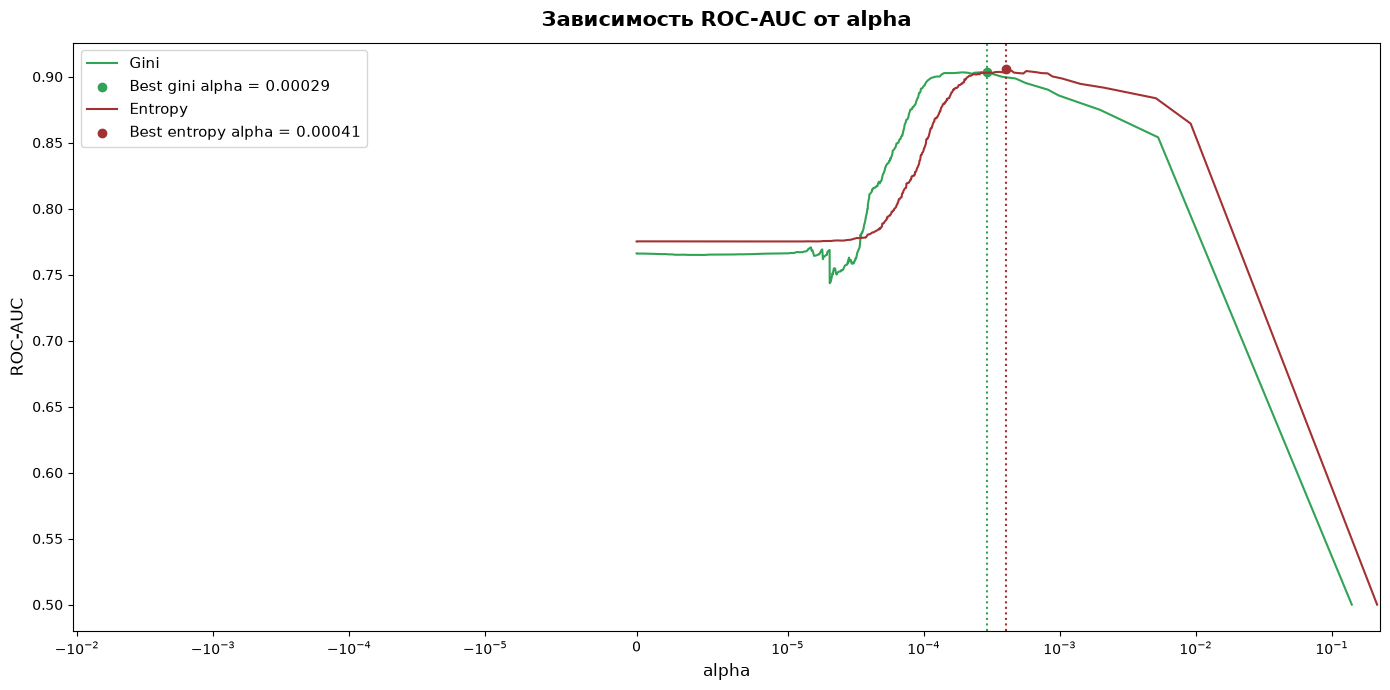

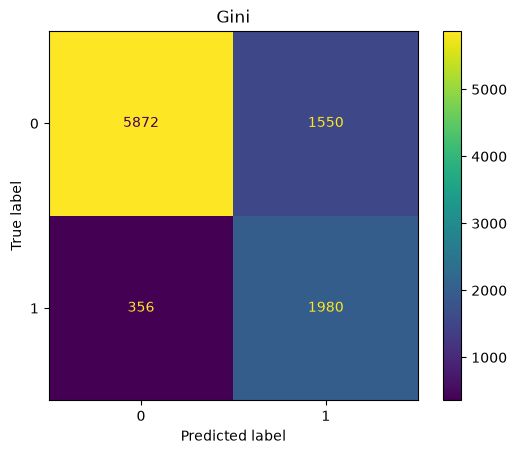

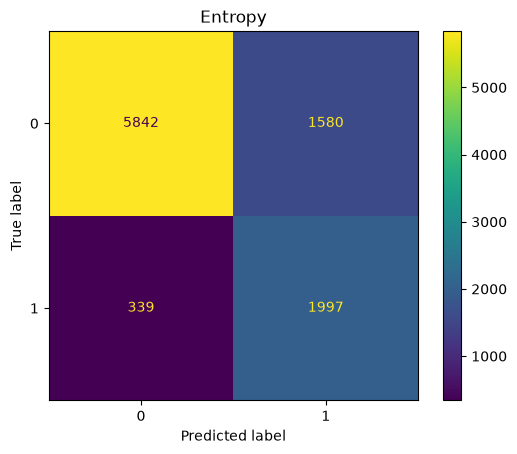

Лучший критерий: entropy (AUC gini=0.9035, entropy=0.9055)
Test ROC-AUC: 0.9142


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

idx_gini = np.argmax(val_gini)
idx_entropy = np.argmax(val_entropy)
alpha_gini = alphas_gini[idx_gini]
alpha_entropy = alphas_entropy[idx_entropy]

plt.figure(figsize=(14, 7))
plt.plot(alphas_gini, val_gini, color="#31a354", label="Gini")
plt.scatter(alpha_gini, val_gini[idx_gini], color="#31a354",
             label=f'Best gini alpha = {alpha_gini:.5f}')
plt.axvline(alpha_gini, color="#31a354", linestyle=':')

plt.plot(alphas_entropy, val_entropy, color="#a33131", label="Entropy")
plt.scatter(alpha_entropy, val_entropy[idx_entropy], color="#a33131",
            label=f'Best entropy alpha = {alpha_entropy:.5f}')
plt.axvline(alpha_entropy, color="#a33131", linestyle=':')

plt.xscale("symlog", linthresh=1e-5)
plt.xlabel('alpha', fontsize=12)
plt.ylabel('ROC-AUC', fontsize=12)
plt.title('Зависимость ROC-AUC от alpha', fontsize=15, fontweight='bold', pad=12)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

def best_model(criterion, alphas, scores):
    best_i = np.argmax(scores)
    clf = DecisionTreeClassifier(criterion=criterion, ccp_alpha=alphas[best_i],
                                 class_weight='balanced', random_state=42)
    clf.fit(X_train, y_train)
    return clf

best_gini = best_model('gini', alphas_gini, val_gini)
best_entropy = best_model('entropy', alphas_entropy, val_entropy)

cm_gini = confusion_matrix(y_val, best_gini.predict(X_val))
cm_entropy = confusion_matrix(y_val, best_entropy.predict(X_val))

ConfusionMatrixDisplay(cm_gini).plot()
plt.title("Gini")
plt.show()

ConfusionMatrixDisplay(cm_entropy).plot()
plt.title("Entropy")
plt.show()

auc_gini = max(val_gini)
auc_entropy = max(val_entropy)

if auc_gini >= auc_entropy:
    winner, winner_name = best_gini, "gini"
else:
    winner, winner_name = best_entropy, "entropy"

print(f"Лучший критерий: {winner_name} (AUC gini={auc_gini:.4f}, entropy={auc_entropy:.4f})")

test_auc = roc_auc_score(y_holdout, winner.predict_proba(X_holdout)[:, 1])
print(f"Test ROC-AUC: {test_auc:.4f}")

### Задача 5. Расширение `MyDecisionTreeClassifier` [2 балла]

В учебный класс добавим порог локального уменьшения неоднородности `min_gain` и веса классов. Этот порог останавливает рост дерева во время обучения и отличается от post-pruning через `ccp_alpha` в sklearn. Здесь `min_gain` относится к текущему узлу. Параметр `min_impurity_decrease` в sklearn дополнительно взвешивает уменьшение долей узла во всей обучающей выборке.

In [ ]:
from typing import Optional, Union, Dict

class _Node:
    """Вершина дерева (и внутренний узел, и лист)."""
    def __init__(self, feat=None, thr=None, left=None, right=None,
                 proba=None, label=None):
        self.feat = feat      # Индекс признака для сплита
        self.thr = thr        # Порог сплита
        self.left = left      # Левая ветка
        self.right = right    # Правая ветка
        self.proba = proba    # Вероятности классов (только в листе)
        self.label = label    # Метка класса (только в листе)

    def is_leaf(self):
        """Возвращает True, если вершина является листом."""
        return self.label is not None


class MyDecisionTreeClassifier:
    """
    Мини-реализация дерева классификации (критерий Gini,
    бинарные сплиты по порогу).
    """

    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",                     # #### NEW
        class_weight: Union[str, Dict[int, float], None] = None,  # #### NEW — твоё следующее задание
        min_gain: float = 0.0,                      # #### NEW — твоё следующее задание
        random_state: Optional[int] = None           # #### NEW
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion                   # #### NEW
        self.class_weight = class_weight             # #### NEW — твоё следующее задание
        self.min_gain = float(min_gain)            # #### NEW — твоё следующее задание
        self.random_state = random_state  # Разбиения перебираются детерминированно

    # ---------- Методы, реализованные вручную ----------
    def _make_leaf(self, y_subset: np.ndarray) -> _Node:
        """
        Превращает подмножество объектов в лист и
        возвращает объект `_Node` с полями `proba`, `label`.
        """
        counts = np.bincount(y_subset, weights=self.class_weights_[y_subset], minlength=self.n_classes_)
        proba  = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        """
        Спускает один объект по дереву до листа
        и возвращает предсказанный класс.
        """
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        """
        Возвращает вектор прогнозов для всей матрицы `X`.

        Обрати внимание: мы сразу преобразуем X в numpy-массив,
        чтобы не индексировать строки как строки или pandas-объекты.
        """
        X_arr = np.asarray(X, dtype=float)
        return self.classes_[np.array([self._predict_one(row, self.root_) for row in X_arr])]

    # ----------------------------------------------------

    # ---------- Готовые вспомогательные методы ----------
    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:             # NEW
        p = counts / counts.sum()
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:      # NEW
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _best_split(self, X: np.ndarray, y: np.ndarray):
        """
        Перебирает все признаки и ищет порог,
        дающий максимальный прирост информации.
        Возвращает (feat, thr). Если сплита нет — (None, None).
        """
        best_gain, best_feat, best_thr = -np.inf, None, None
        parent_imp = self._impurity(np.bincount(y, weights=self.class_weights_[y], minlength=self.n_classes_))
        for feat in range(X.shape[1]):
            xs = X[:, feat]
            order = np.argsort(xs)
            xs_sort, y_sort = xs[order], y[order]
            right = np.bincount(y_sort, weights=self.class_weights_[y_sort], minlength=self.n_classes_).astype(float)
            left  = np.zeros_like(right)
            for i in range(1, len(y_sort)):
                cls = y_sort[i - 1]
                left[cls]  += self.class_weights_[cls]
                right[cls] -= self.class_weights_[cls]
                if xs_sort[i] == xs_sort[i - 1]:
                    continue
                if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                    continue
                wL = left.sum() / (left.sum() + right.sum())
                wR = 1 - wL
                gain = parent_imp - (wL * self._impurity(left) + wR * self._impurity(right))
                if gain > best_gain:
                    best_gain, best_feat = gain, feat
                    best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, depth: int = 0) -> _Node:
        """
        Рекурсивно строит дерево, возвращая корневой узел `_Node`.
        """
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y)

        feat, thr = self._best_split(X, y)
        if feat is None:
            return self._make_leaf(y)

        mask = X[:, feat] <= thr
        left  = self._grow(X[mask],  y[mask],  depth + 1)
        right = self._grow(X[~mask], y[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def fit(self, X, y):
        """
        Строит дерево по обучающим данным.
        Если `y` содержит строковые метки, сначала преобразует их в целые.
        """
        # Приводим X, y к numpy-массиву целых
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)

        self.classes_, y_arr = np.unique(y_arr.ravel(), return_inverse=True)
        self.n_classes_ = len(self.classes_)
        self.class_weights_ = np.ones(self.n_classes_)

        self.root_ = self._grow(X_arr, y_arr)
        return self

Давай дополним этот класс.





#### Задача 5.1 [0,5 балла]

В `_best_split` используй выбранный `criterion` в родителе и обоих потомках. После поиска лучшего сплита верни `(None, None)`, если уменьшение взвешенной неоднородности не превосходит `self.min_gain`. Уменьшение здесь считается относительно текущего узла. При пороге 0 сохраняй только строго улучшающие разбиения.

In [ ]:
# Напиши код здесь
def _best_split(self, X: np.ndarray, y: np.ndarray):
    """
    Перебирает все признаки и ищет порог,
    дающий максимальный прирост информации.
    Возвращает (feat, thr). Если сплита нет — (None, None).
    """
    best_gain, best_feat, best_thr = -np.inf, None, None
    parent_imp = self._impurity(np.bincount(y, weights=self.class_weights_[y], minlength=self.n_classes_))
    for feat in range(X.shape[1]):
        xs = X[:, feat]
        order = np.argsort(xs)
        xs_sort, y_sort = xs[order], y[order]
        right = np.bincount(y_sort, weights=self.class_weights_[y_sort], minlength=self.n_classes_).astype(float)
        left  = np.zeros_like(right)
        for i in range(1, len(y_sort)):
            cls = y_sort[i - 1]
            left[cls]  += self.class_weights_[cls]
            right[cls] -= self.class_weights_[cls]
            if xs_sort[i] == xs_sort[i - 1]:
                continue
            if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                continue
            wL = left.sum() / (left.sum() + right.sum())
            wR = 1 - wL
            gain = parent_imp - (wL * self._impurity(left) + wR * self._impurity(right))
            if gain > best_gain:
                best_gain, best_feat = gain, feat
                best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
    if best_gain <= self.min_gain:
        return None, None
    return best_feat, best_thr

#### Задача 5.2 [0,5 балла]

В `fit` закодируй все метки через `np.unique(..., return_inverse=True)` и сохрани `self.classes_`. Вычисли `self.class_weights_`: единицы без весов, n/(K*n_k) для balanced или значения словаря по исходным меткам. Готовые методы базового класса уже используют этот массив в листьях и при выборе сплита. Проверь, что веса действительно меняют результат на небольшом несбалансированном примере.

In [ ]:
def fit(self, X, y):
    X_arr = np.asarray(X, dtype=float)
    self.classes_, y_arr = np.unique(np.asarray(y).ravel(), return_inverse=True)
    self.n_classes_ = len(self.classes_)
    # Создай self.class_weights_ по правилу из условия.
    # Напиши код здесь
    if self.class_weight is None:
        self.class_weights_ = np.ones(self.n_classes_)
    elif self.class_weight == 'balanced':
        n = len(y_arr)
        counts = np.bincount(y_arr, minlength=self.n_classes_)
        self.class_weights_ = n / (self.n_classes_ * counts)
    else:
        weights = np.ones(self.n_classes_)
        for label, weight in self.class_weight.items():
            idx = np.flatnonzero(self.classes_ == label)
            if len(idx):
                weights[idx] = weight
        self.class_weights_ = weights

    self.root_ = self._grow(X_arr, y_arr)
    return self

#### Задача 5.3 [Обязательная]

Собери итоговый класс. В нём веса объектов передаются явно через аргумент `w`. Адаптируй `_best_split` к взвешенным частотам. В `fit` создай веса объектов как `self.class_weights_[y_arr]` и передай их в `_grow`. `min_samples_leaf` и `min_samples_split` ограничивают число объектов, а не сумму весов.

Без собранного работоспособного класса баллы за задачу 5 не начисляются.

In [ ]:
from typing import Optional, Union, Dict


class _Node:
    def __init__(self, feat=None, thr=None, left=None, right=None, proba=None, label=None):
        self.feat = feat
        self.thr = thr
        self.left = left
        self.right = right
        self.proba = proba
        self.label = label

    def is_leaf(self):
        return self.label is not None


class MyDecisionTreeClassifier:
    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",
        class_weight: Union[str, Dict[int, float], None] = None,
        min_gain: float = 0.0,
        random_state: Optional[int] = None
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.class_weight = class_weight
        self.min_gain = float(min_gain)
        self.random_state = random_state  # Детерминированный перебор разбиений

    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _make_leaf(self, y_subset: np.ndarray, w_subset: np.ndarray) -> _Node:
        counts = np.bincount(y_subset, weights=w_subset, minlength=self.n_classes_)
        proba = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _best_split(self, X: np.ndarray, y: np.ndarray, w: np.ndarray):
        best_gain, best_feat, best_thr = -np.inf, None, None
        parent_counts = np.bincount(y, weights=w, minlength=self.n_classes_)
        parent_imp = self._impurity(parent_counts)
        total_w = parent_counts.sum()
        for feat in range(X.shape[1]):
            xs = X[:, feat]
            order = np.argsort(xs)
            xs_sort, y_sort, w_sort = xs[order], y[order], w[order]
            right = np.bincount(y_sort, weights=w_sort, minlength=self.n_classes_).astype(float)
            left  = np.zeros_like(right)
            for i in range(1, len(y_sort)):
                cls = y_sort[i - 1]
                left[cls]  += w_sort[i - 1]
                right[cls] -= w_sort[i - 1]
                if xs_sort[i] == xs_sort[i - 1]:
                    continue
                if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                    continue
                wL = left.sum() / total_w
                wR = 1.0 - wL
                gain = parent_imp - (wL * self._impurity(left) + wR * self._impurity(right))
                if gain > best_gain:
                    best_gain, best_feat = gain, feat
                    best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
        if best_gain <= self.min_gain:
            return None, None
        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, w: np.ndarray, depth: int = 0) -> _Node:
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y, w)
        feat, thr = self._best_split(X, y, w)
        if feat is None:
            return self._make_leaf(y, w)
        mask = X[:, feat] <= thr
        left = self._grow(X[mask], y[mask], w[mask], depth + 1)
        right = self._grow(X[~mask], y[~mask], w[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        if not hasattr(self, "root_"):
            raise ValueError("Сначала вызови fit")
        return self.classes_[np.array([self._predict_one(row, self.root_) for row in X_arr])]

    def predict_proba(self, X):
        X_arr = np.asarray(X, dtype=float)
        if not hasattr(self, "root_"):
            raise ValueError("Сначала вызови fit")
        probs = []
        for row in X_arr:
            node = self.root_
            while not node.is_leaf():
                node = node.left if row[node.feat] <= node.thr else node.right
            probs.append(node.proba)
        return np.vstack(probs)

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        self.classes_, y_arr = np.unique(np.asarray(y).ravel(), return_inverse=True)
        self.n_classes_ = len(self.classes_)
        if self.class_weight is None:
            self.class_weights_ = np.ones(self.n_classes_)
        elif self.class_weight == 'balanced':
            n = len(y_arr)
            counts = np.bincount(y_arr, minlength=self.n_classes_)
            self.class_weights_ = n / (self.n_classes_ * counts)
        else:
            weights = np.ones(self.n_classes_)
            for label, weight in self.class_weight.items():
                idx = np.flatnonzero(self.classes_ == label)
                if len(idx):
                    weights[idx[0]] = weight
            self.class_weights_ = weights
        sample_w = self.class_weights_[y_arr]
        self.root_ = self._grow(X_arr, y_arr, sample_w)
        return self

In [ ]:
# 5.2
X_small = np.arange(9).reshape(-1, 1).astype(float)
y_small = np.array([0, 1, 0, 1, 0, 0, 0, 0, 0])

t_none = MyDecisionTreeClassifier(max_depth=1, class_weight=None).fit(X_small, y_small)
t_bal  = MyDecisionTreeClassifier(max_depth=1, class_weight='balanced').fit(X_small, y_small)

print("None weights:", t_none.class_weights_)
print("balanced weights:", t_bal.class_weights_)
print("None pred:", t_none.predict(X_small))
print("balanced pred:", t_bal.predict(X_small))

assert not np.array_equal(t_none.predict(X_small), t_bal.predict(X_small))
print("OK: веса изменили предсказание")

None weights: [1. 1.]
balanced weights: [0.64285714 2.25      ]
None pred: [0 0 0 0 0 0 0 0 0]
balanced pred: [1 1 1 1 0 0 0 0 0]
OK: веса изменили предсказание


#### Задача 5.4 [1 балл]

Обучи итоговый класс на Adult с `criterion="gini"`. Начни с `max_depth=5`, `min_samples_leaf=20`, `class_weight="balanced"`, `min_gain=0`. Рассчитай validation ROC-AUC по вероятности класса 1 и сравни со sklearn при тех же ограничениях и весах. Если меняешь настройки, используй validation. Фиксированного обязательного порога ROC-AUC здесь нет.

In [ ]:
# Напиши код здесь: создай custom_tree, обучи на train и рассчитай validation ROC-AUC.
# Для столбца вероятности используй np.flatnonzero(custom_tree.classes_ == 1)[0].
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier

custom_tree = MyDecisionTreeClassifier(
    max_depth=5, min_samples_split=2, min_samples_leaf=20,
    criterion='gini', class_weight='balanced', min_gain=0.0)
custom_tree.fit(X_train, y_train)

col1 = np.flatnonzero(custom_tree.classes_ == 1)[0]
custom_auc = roc_auc_score(y_val, custom_tree.predict_proba(X_val)[:, col1])

# sklearn с теми же ограничениями и весами
sk = DecisionTreeClassifier(max_depth=5, min_samples_split=2, min_samples_leaf=20,
            criterion='gini', class_weight='balanced', random_state=42)
sk.fit(X_train, y_train)
sk_auc = roc_auc_score(y_val, sk.predict_proba(X_val)[:, 1])

print(f"custom ROC-AUC: {custom_auc:.4f}")
print(f"sklearn ROC-AUC: {sk_auc:.4f}")

custom ROC-AUC: 0.8865
sklearn ROC-AUC: 0.8867


### Теоретические вопросы [1 балл]

1. Как влияют гиперпараметры `max_depth, min_samples_split, min_samples_leaf` на bias-variance дерева решений? [0.5 балла]


max_depth
- малые значения - высокое смещение, низкая дисперсия
- большое значени - низкое смещение, высокая дисперсия

min_samples_split
- малое значение - низкое смещение, высокая дисперсия
- большое значение - высокое смещение, низкая дисперсия

min_samples_leaf
- малое значение - низкое смещение, высокая дисперсия
- большое значение - высокое смещение, низкая дисперсия

Оптимальные значения будут лежать там где arg(min(bias^2 + variance + noise))

2. Почему один и тот же датасет может давать такие разные деревья при малых изменениях данных? [0.5 балла]
Потому что дерево строится жадно, каждый сплит зависит от предыдущего. Если из-за небольшого сдвига данных корневой признак или порог чуть поменялись, то все поддеревья ниже строятся уже по другим данным и становятся совершенно другими.

----------------------------------------------------------------